In [1]:
import matplotlib.pyplot as plt
import numpy as np
from numpy.typing import NDArray
from typing import Tuple

In [2]:
from mcap.reader import make_reader

mcap_file_path_outer = "../data/outer.mcap"
mcap_file_path_inner_1 = "../data/inner1.mcap"
mcap_file_path_inner_2 = "../data/inner2.mcap"


with open(mcap_file_path_outer, "rb") as f:
    reader = make_reader(f)

    # 1. Zusammenfassung der Datei laden
    summary = reader.get_summary()

    if summary:
        print("--- ALLGEMEINE STATISTIKEN ---")
        stats = summary.statistics
        print(f"Nachrichten insgesamt: {stats.message_count}")
        print(f"Anzahl Kanäle/Topics: {stats.channel_count}")
        print(f"Startzeit (Nanosekunden): {stats.message_start_time}")
        print(f"Endzeit (Nanosekunden): {stats.message_end_time}")

        print("\n--- REGISTRIERTE SCHEMATA (Datentypen) ---")
        for schema_id, schema in summary.schemas.items():
            print(f"ID {schema_id}: {schema.name} (Typ: {schema.encoding})")

        print("\n--- AKTIVE KANÄLE (Topics) ---")
        for channel_id, channel in summary.channels.items():
            # Zugehöriges Schema finden
            schema_name = summary.schemas[channel.schema_id].name if channel.schema_id in summary.schemas else "Kein Schema"
            print(f"Topic: '{channel.topic}' | Typ: {schema_name} | Encoding: {channel.message_encoding}")
    else:
        print("Die Datei enthält keine Summary-Sektion. Sie muss sequenziell gescannt werden.")


--- ALLGEMEINE STATISTIKEN ---
Nachrichten insgesamt: 20654
Anzahl Kanäle/Topics: 2
Startzeit (Nanosekunden): 1760100720466395132
Endzeit (Nanosekunden): 1760100761770344943

--- REGISTRIERTE SCHEMATA (Datentypen) ---
ID 1: tf2_msgs/msg/TFMessage (Typ: ros2msg)
ID 2: nav_msgs/msg/Odometry (Typ: ros2msg)

--- AKTIVE KANÄLE (Topics) ---
Topic: '/tf' | Typ: tf2_msgs/msg/TFMessage | Encoding: cdr
Topic: '/mapping_tool/odometry' | Typ: nav_msgs/msg/Odometry | Encoding: cdr


In [3]:
from mcap_ros2.decoder import DecoderFactory

def decode_msg(path: str, get_data: bool) -> Tuple[NDArray, NDArray] | Tuple[None, None]:
    x = []
    y = []

    with open(path, "rb") as f:
        reader = make_reader(f, decoder_factories=[DecoderFactory()])

        for i, (schema, channel, message, msg) in enumerate(
            reader.iter_decoded_messages(topics=["/mapping_tool/odometry"])
        ):
            position = msg.pose.pose.position
            orientation = msg.pose.pose.orientation

            if get_data:
                x.append(position.x)
                y.append(position.y)
            else:
                print(f"\nMessage {i}")
                print(f"Reference frame: {msg.header.frame_id}")
                print(f"Tracked frame:   {msg.child_frame_id}")
                print(f"Stamp: {msg.header.stamp.sec} s + "
                      f"{msg.header.stamp.nanosec} ns")
                print(f"Position: x={position.x}, y={position.y}, z={position.z}")
                print(f"Orientation: x={orientation.x}, y={orientation.y}, "
                      f"z={orientation.z}, w={orientation.w}")

                if i >= 5:
                    break

    if get_data:
        return np.array(x), np.array(y)
    else:
        return None, None

decode_msg(mcap_file_path_outer, False)


Message 0
Reference frame: map
Tracked frame:   mapping_tool
Stamp: 1760100720 s + 465906381 ns
Position: x=5.059316551904079, y=1.3268272487936903, z=0.08821270138543513
Orientation: x=-0.16142994109611974, y=0.18071925762450788, z=-0.6381023476232041, w=-0.7306191234216537

Message 1
Reference frame: map
Tracked frame:   mapping_tool
Stamp: 1760100720 s + 469913244 ns
Position: x=5.059267490659031, y=1.3270119336776356, z=0.08818160209009013
Orientation: x=-0.1614467771157722, y=0.1807628366523565, z=-0.6379791932227425, w=-0.730712166019906

Message 2
Reference frame: map
Tracked frame:   mapping_tool
Stamp: 1760100720 s + 473875522 ns
Position: x=5.059213087974381, y=1.327079304935023, z=0.08821466269022626
Orientation: x=-0.161457367351092, y=0.18082365464427644, z=-0.6378195677229123, w=-0.7308341186543084

Message 3
Reference frame: map
Tracked frame:   mapping_tool
Stamp: 1760100720 s + 477876663 ns
Position: x=5.059206019430512, y=1.327207555721846, z=0.08824640939531841
Orie

(None, None)

In [4]:
x_outer, y_outer = decode_msg(mcap_file_path_outer, True)

x_inner_1, y_inner_1 = decode_msg(mcap_file_path_inner_1, True)

x_inner_2, y_inner_2 = decode_msg(mcap_file_path_inner_2, True)

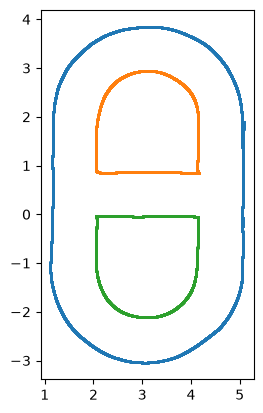

In [5]:
plt.scatter(x_outer, y_outer, s=1)
plt.scatter(x_inner_1, y_inner_1, s=1)
plt.scatter(x_inner_2, y_inner_2, s=1)

plt.gca().set_aspect("equal", adjustable="box")

# plt.xlim(-4, 6)
# plt.ylim(-4, 6)